In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from corner import corner, overplot_lines, overplot_points
from jax import jit
from scipy.stats import qmc
from scipy.stats import t as stuent_t
from raddest.reg.func import generate_piecewise_linear
from utils.linear_model import get_ODR, get_OLS, xy2logxy


In [ ]:
n_piece = 3
b0 = 0.0
x0 = -0.4
k_lst = [0.5, 1.2, 0.5]
dx_lst = [0.8]
sig = 0.1
N = 10000

k_main = k_lst[1]
b_main = k_lst[0] * x0 + b0 - k_lst[1] * x0

piecewise_linear = generate_piecewise_linear(n_piece)

x = 10**np.random.normal(0, 0.3, size=N)

y = 10**(piecewise_linear(np.log10(x), b0=b0, x0=x0, k_lst=k_lst, dx_lst=dx_lst) +
         np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

Text(0, 0.5, 'log(y)')

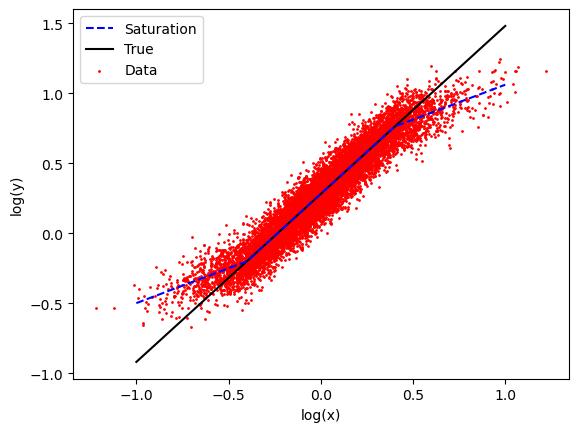

In [ ]:
log_xx = np.linspace(-1, 1, 1000)
log_yy = k_main * log_xx + b_main
log_yy_sat = piecewise_linear(log_xx, b0=b0, x0=x0, k_lst=k_lst, dx_lst=dx_lst)
plt.plot(log_xx,
         log_yy_sat,
         color='blue',
         label='Saturation',
         zorder=10,
         linestyle='--')
plt.plot(log_xx, log_yy, color='black', label='True')
plt.scatter(np.log10(x), np.log10(y), color='red', label='Data', s=1)
plt.legend()
plt.xlabel('log(x)')
plt.ylabel('log(y)')

In [ ]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:39: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:40: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)
2026-11-24 20:14:12.657254: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [ ]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

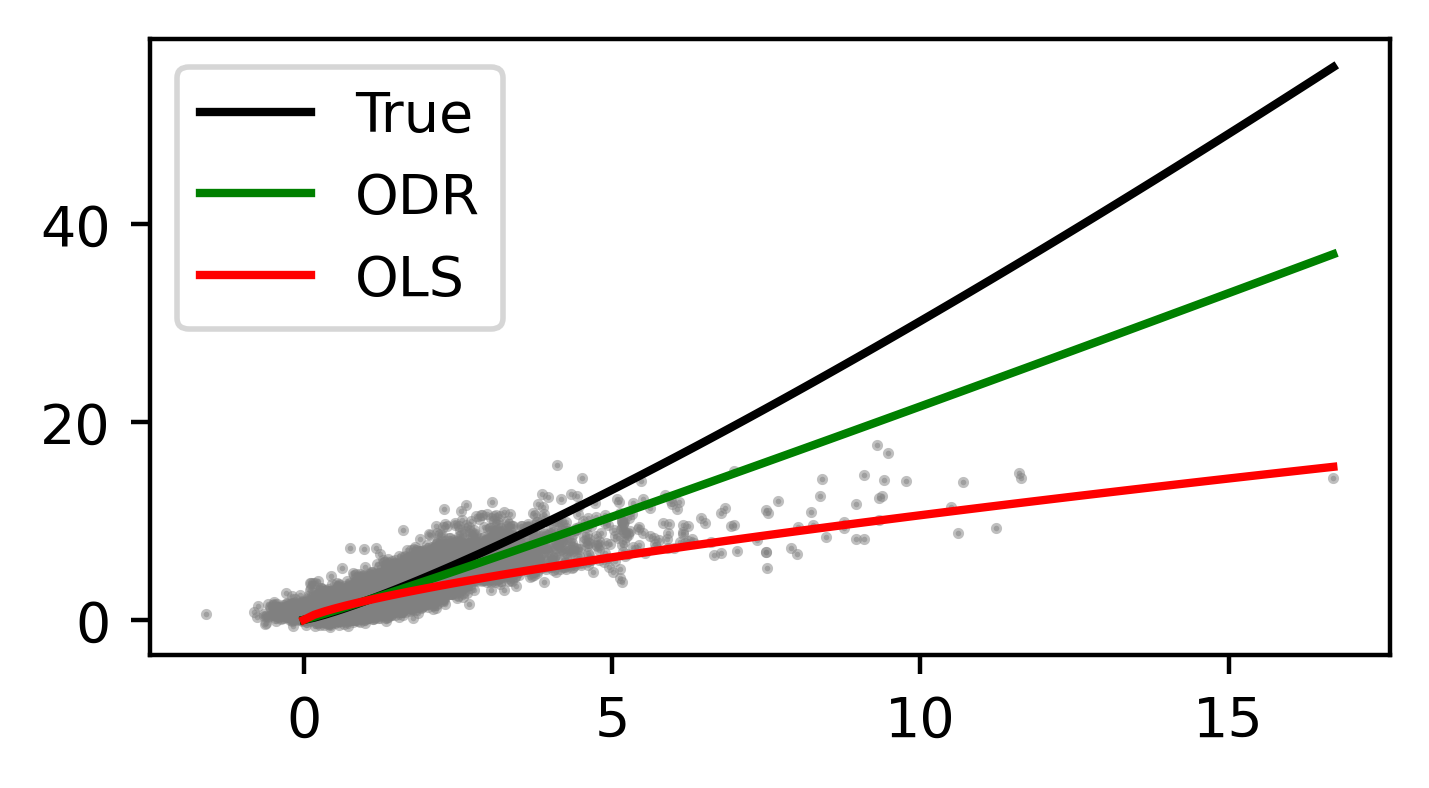

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k_main * np.log10(xx) + b_main)
# yy_sat = 10**linear_sigmoid(np.log10(xx), k, b, x0, x1, c0, c1)
yy_ODR = 10**res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10**res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from jax.scipy.stats import norm

from raddest.api.fitter import (LogLinearKS, LogLinearML, LogLinearStudentTML)
from raddest.api.flowvi import FlowVI
from raddest.reg.map import get_w_add_lognorm
from raddest.transfer import NegLogPlus

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:06<11:29,  6.97s/it]

  6%|▌         | 6/100 [00:07<01:22,  1.14it/s]

 11%|█         | 11/100 [00:07<00:35,  2.50it/s]

 16%|█▌        | 16/100 [00:07<00:19,  4.31it/s]

 21%|██        | 21/100 [00:07<00:11,  6.67it/s]

... (15 outputs left out)

step 10: loss 0.3159731924533844
step 20: loss 0.30898600816726685


step 30: loss 0.302923321723938
step 40: loss 0.3016465902328491


step 50: loss 0.29874423146247864
step 60: loss 0.29765716195106506


step 70: loss 0.31389254331588745


In [ ]:
xflow.ks_test(x_obs, x_err, N=10000)

(0.021549977362155914, 0.09725932072386492)

In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:06<10:56,  6.63s/it]

  6%|▌         | 6/100 [00:06<01:18,  1.20it/s]

 12%|█▏        | 12/100 [00:06<00:30,  2.91it/s]

 18%|█▊        | 18/100 [00:06<00:15,  5.16it/s]

 24%|██▍       | 24/100 [00:07<00:09,  8.05it/s]

... (13 outputs left out)

step 0: loss 1.0062681436538696
step 10: loss 0.974117636680603


step 20: loss 0.9744994640350342
step 30: loss 0.966340184211731


step 40: loss 0.9634341597557068
step 50: loss 0.9615228176116943


step 60: loss 0.9608209729194641


In [ ]:
yflow.ks_test(y_obs, y_err, N=10000)

(0.012399992905557156, 0.69876194987956)

### Normal Model

In [ ]:
loglinear_ML = LogLinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = loglinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0030196 0.012296541 0.12458048 -0.654376


1000 1.0573386 0.27796823 0.11671085 0.53347754


2000 1.0595278 0.27764207 0.11666299 0.5334849


3000 1.0596809 0.27761915 0.116659805 0.5334849
converged, so stop with 3000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k_main, b_main, sig)

ML fitted: 1.0596809 0.27761915 0.116659805
Truth: 1.2 0.27999999999999997 0.1


### T Model

In [ ]:
logLinear_studentT_ML = LogLinearStudentTML(xflow, yflow)

In [ ]:
params_ml_t, params_std_t, cov_t = logLinear_studentT_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 2., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0007024 0.005034533 1.9999173 0.105429165 -0.3506233


1000 1.0772163 0.28060693 2.0237694 0.068579994 0.5100157


2000 1.080849 0.2800502 2.0442011 0.068810016 0.5104532


3000 1.0810071 0.27999005 2.0640957 0.06914596 0.51085013


4000 1.0809025 0.27996796 2.0835218 0.06947811 0.51122636


5000 1.0808003 0.27994746 2.1024868 0.06979816 0.51158726


... (172 outputs left out)

178000 1.0754187 0.27895588 3.53145 0.08571842 0.5253997


179000 1.0754062 0.27895376 3.5362184 0.08575348 0.52542174


180000 1.075394 0.27895173 3.5408244 0.0857873 0.52544427


181000 1.0753822 0.27894974 3.5453544 0.08582047 0.52546465
converged, so stop with 181000 iterations


In [ ]:
print('ML fitted:', *params_ml_t)
print('Truth:', k_main, b_main, sig)

ML fitted: 1.0753822 0.27894974 3.5453544 0.08582047
Truth: 1.2 0.27999999999999997 0.1


In [ ]:
q_16, q_84 = stuent_t.ppf([0.16, 0.84],
                          float(params_ml_t[-2]),
                          scale=float(params_ml_t[-1]))
(q_84 - q_16) / 2

0.09911179146985954

### KS

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.163 +/- 0.055
b: 0.296 +/- 0.015
sig: 0.129 +/- 0.038


----
k: 1.172 +/- 0.078
b: 0.275 +/- 0.010
sig: 0.085 +/- 0.061


----
k: 1.152 +/- 0.073
b: 0.279 +/- 0.022
sig: 0.100 +/- 0.054


----
k: 1.173 +/- 0.076
b: 0.275 +/- 0.022
sig: 0.089 +/- 0.057


----
k: 1.162 +/- 0.072
b: 0.278 +/- 0.022
sig: 0.103 +/- 0.061


... (3 outputs left out)

----
k: 1.169 +/- 0.075
b: 0.274 +/- 0.021
sig: 0.097 +/- 0.062


----
k: 1.159 +/- 0.071
b: 0.280 +/- 0.021
sig: 0.096 +/- 0.060


----
k: 1.174 +/- 0.081
b: 0.275 +/- 0.022
sig: 0.091 +/- 0.061
max iteration reached


[1.16784211 0.27657026 0.0955591 ] [0.07556107 0.01537164 0.05555055]


In [ ]:
print('KS fitted:', *params_mean)
print('Truth:', k_main, b_main, sig)

KS fitted: 1.1678421066744824 0.276570261482216 0.09555910217207096
Truth: 1.2 0.27999999999999997 0.1


### Piecewise Log-Linear ML

In [ ]:
from raddest.api.fitter import PiecewiseLogLinearML

In [ ]:
piecewise_loglinear = PiecewiseLogLinearML(xflow, yflow, 3, width=0.1)

In [ ]:
q5 = np.log10(np.percentile(x_obs, 5))
q95 = np.log10(np.percentile(x_obs, 95))
params0 = [0., q5] + [1., 1., 1.] + [q95 - q5] + [0.2]
# params0 = (b0, x0) + k_lst + dx_lst + sig

params_ml_piecewise, params_std_piecewise, cov_piecewise = piecewise_loglinear.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=params0,
    ignore_y_err_c_y=True,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 0.0044429097 -0.8299357 0.9963149 1.004352 0.99997795 1.331002 0.20380025 -1.0278921


1000 0.107250415 -0.8654624 0.9088986 1.1021236 0.93749344 1.3037506 0.111276396 -0.39957005


2000 0.09699828 -0.89037704 0.9162615 1.1167413 0.8713652 1.2750962 0.10818028 -0.39333808


3000 0.08601235 -0.9007156 0.9249215 1.1354641 0.81695294 1.2610985 0.105992794 -0.38946643


4000 0.078373566 -0.90050983 0.93098336 1.1493063 0.77449363 1.2585219 0.10463862 -0.38734785


5000 0.07425747 -0.8970063 0.9340777 1.1570529 0.7399297 1.2601256 0.10376401 -0.38604352


... (27 outputs left out)

33000 0.07217727 -0.83917594 0.9107935 1.1496425 0.49092603 1.2775192 0.101445876 -0.38207537


34000 0.07177953 -0.83792424 0.9097817 1.1494644 0.48923588 1.2767787 0.10144436 -0.38206923


35000 0.07135299 -0.83666986 0.9087685 1.1493225 0.48768428 1.2759584 0.10144236 -0.38206333


36000 0.07092132 -0.835416 0.9077552 1.1491871 0.4862577 1.275124 0.10144067 -0.38205782
converged, so stop with 36000 iterations


In [ ]:
piecewise_loglinear.ks_test(params_ml_piecewise, x_obs, y_obs)

(0.01880001276731491, 0.12403740830379491)

In [ ]:
print('Ouecewise ML fitted:', *params_ml_piecewise)
print('Truth:', [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1])

Ouecewise ML fitted: 0.07092132 -0.835416 0.9077552 1.1491871 0.4862577 1.275124 0.10144067
Truth: [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1]


In [ ]:
# as can be seen, the first piece is hard to be constrained. Because the noise is relatively large in small x end.

print('Piecewise ML fitted (k_lst, b_lst, x_lst, sig):',
      *piecewise_loglinear.to_each_piece_params(params_ml_piecewise))
print(
    'Truth (k_lst, b_lst, x_lst, sig):',
    *piecewise_loglinear.to_each_piece_params(
        [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1]))

Piecewise ML fitted (k_lst, b_lst, x_lst, sig): [0.9077552 1.1491871 0.4862577] [0.07092132 0.2726174  0.5641127 ] [-0.835416    0.43970793] 0.1014406681060791
Truth (k_lst, b_lst, x_lst, sig): [0.5 1.2 0.5] [0.   0.28 0.56] [-0.4  0.4] 0.1


In [ ]:
# fix k_lst[1] at its initial value: the equality hyperplane
# k_lst[1] = 1.18 replaces the old is_fixed mechanism
piecewise_loglinear_regressor_fixed = PiecewiseLogLinearML(
    xflow,
    yflow,
    3,
    width=0.1,
    A_eq=[[0., 0., 0., 1., 0., 0., 0.]],
    b_eq=[-1.18])

params0 = [0., q5] + [1., 1.18, 1.] + [q95 - q5] + [0.2]

params_ml_piecewise_fixed, params_std_piecewise_fixed, cov_piecewise_fixed = piecewise_loglinear_regressor_fixed.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=params0,
    ignore_y_err_c_y=True,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 0.0016056616 -0.8302342 0.99866885 -1.1799998 0.99997675 1.330994 0.1992697 -15.247671


1000 0.28386226 0.5013343 0.9332023 -1.18 0.9992501 1.3376079 0.1682533 -0.52506083


2000 0.2716778 0.7102446 1.0558634 -1.18 0.9992501 1.337654 0.11507544 -0.4108074


3000 0.27157247 0.736188 1.0584176 -1.18 0.9992501 1.337654 0.114886515 -0.41001636


4000 0.27195928 0.7455112 1.0567722 -1.18 0.9992501 1.337654 0.1149937 -0.40992177


5000 0.27215704 0.74999243 1.0559372 -1.18 0.9992501 1.337654 0.11507716 -0.4099002


6000 0.2722561 0.75240564 1.0555403 -1.18 0.9992501 1.337654 0.11512938 -0.40989402


7000 0.27230906 0.7537744 1.0553387 -1.18 0.9992501 1.337654 0.11516066 -0.40989214
converged, so stop with 7000 iterations


In [ ]:
print(
    'Piecewise ML fitted, k1 fixed (k_lst, b_lst, x_lst, sig):',
    *piecewise_loglinear_regressor_fixed.to_each_piece_params(
        params_ml_piecewise_fixed))
print(
    'Truth (k_lst, b_lst, x_lst, sig):',
    *piecewise_loglinear_regressor_fixed.to_each_piece_params(
        [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1]))

Piecewise ML fitted, k1 fixed (k_lst, b_lst, x_lst, sig): [ 1.0553387 -1.18       0.9992501] [ 0.27230906  1.9572501  -2.6004949 ] [0.7537744 2.0914283] 0.11516065895557404
Truth (k_lst, b_lst, x_lst, sig): [0.5 1.2 0.5] [0.   0.28 0.56] [-0.4  0.4] 0.1


In [ ]:
initial_state = np.random.uniform(low=[-0.2, -1, 0, 0, 0, 0.5, 0.02],
                                  high=[0.2, 0, 2, 2, 2, 1, 0.3],
                                  size=(28, 7))

In [ ]:
sampler = piecewise_loglinear.get_posterior_mcmc(
    x_obs,
    x_err,
    y_obs,
    y_err,
    ndim=7,
    nsteps=30000,
    initial_state=initial_state,
    ignore_y_err_c_y=True,
    run_mcmc_kwargs={'progress': True})

  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 1/30000 [00:00<3:02:53,  2.73it/s]

  0%|          | 5/30000 [00:00<39:18, 12.72it/s]  

  0%|          | 9/30000 [00:00<25:29, 19.61it/s]

  0%|          | 13/30000 [00:00<20:32, 24.34it/s]

  0%|          | 17/30000 [00:00<18:03, 27.67it/s]

... (7,492 outputs left out)

100%|█████████▉| 29989/30000 [13:59<00:00, 35.42it/s]

100%|█████████▉| 29993/30000 [13:59<00:00, 35.48it/s]

100%|█████████▉| 29997/30000 [13:59<00:00, 35.51it/s]

100%|██████████| 30000/30000 [14:00<00:00, 35.71it/s]

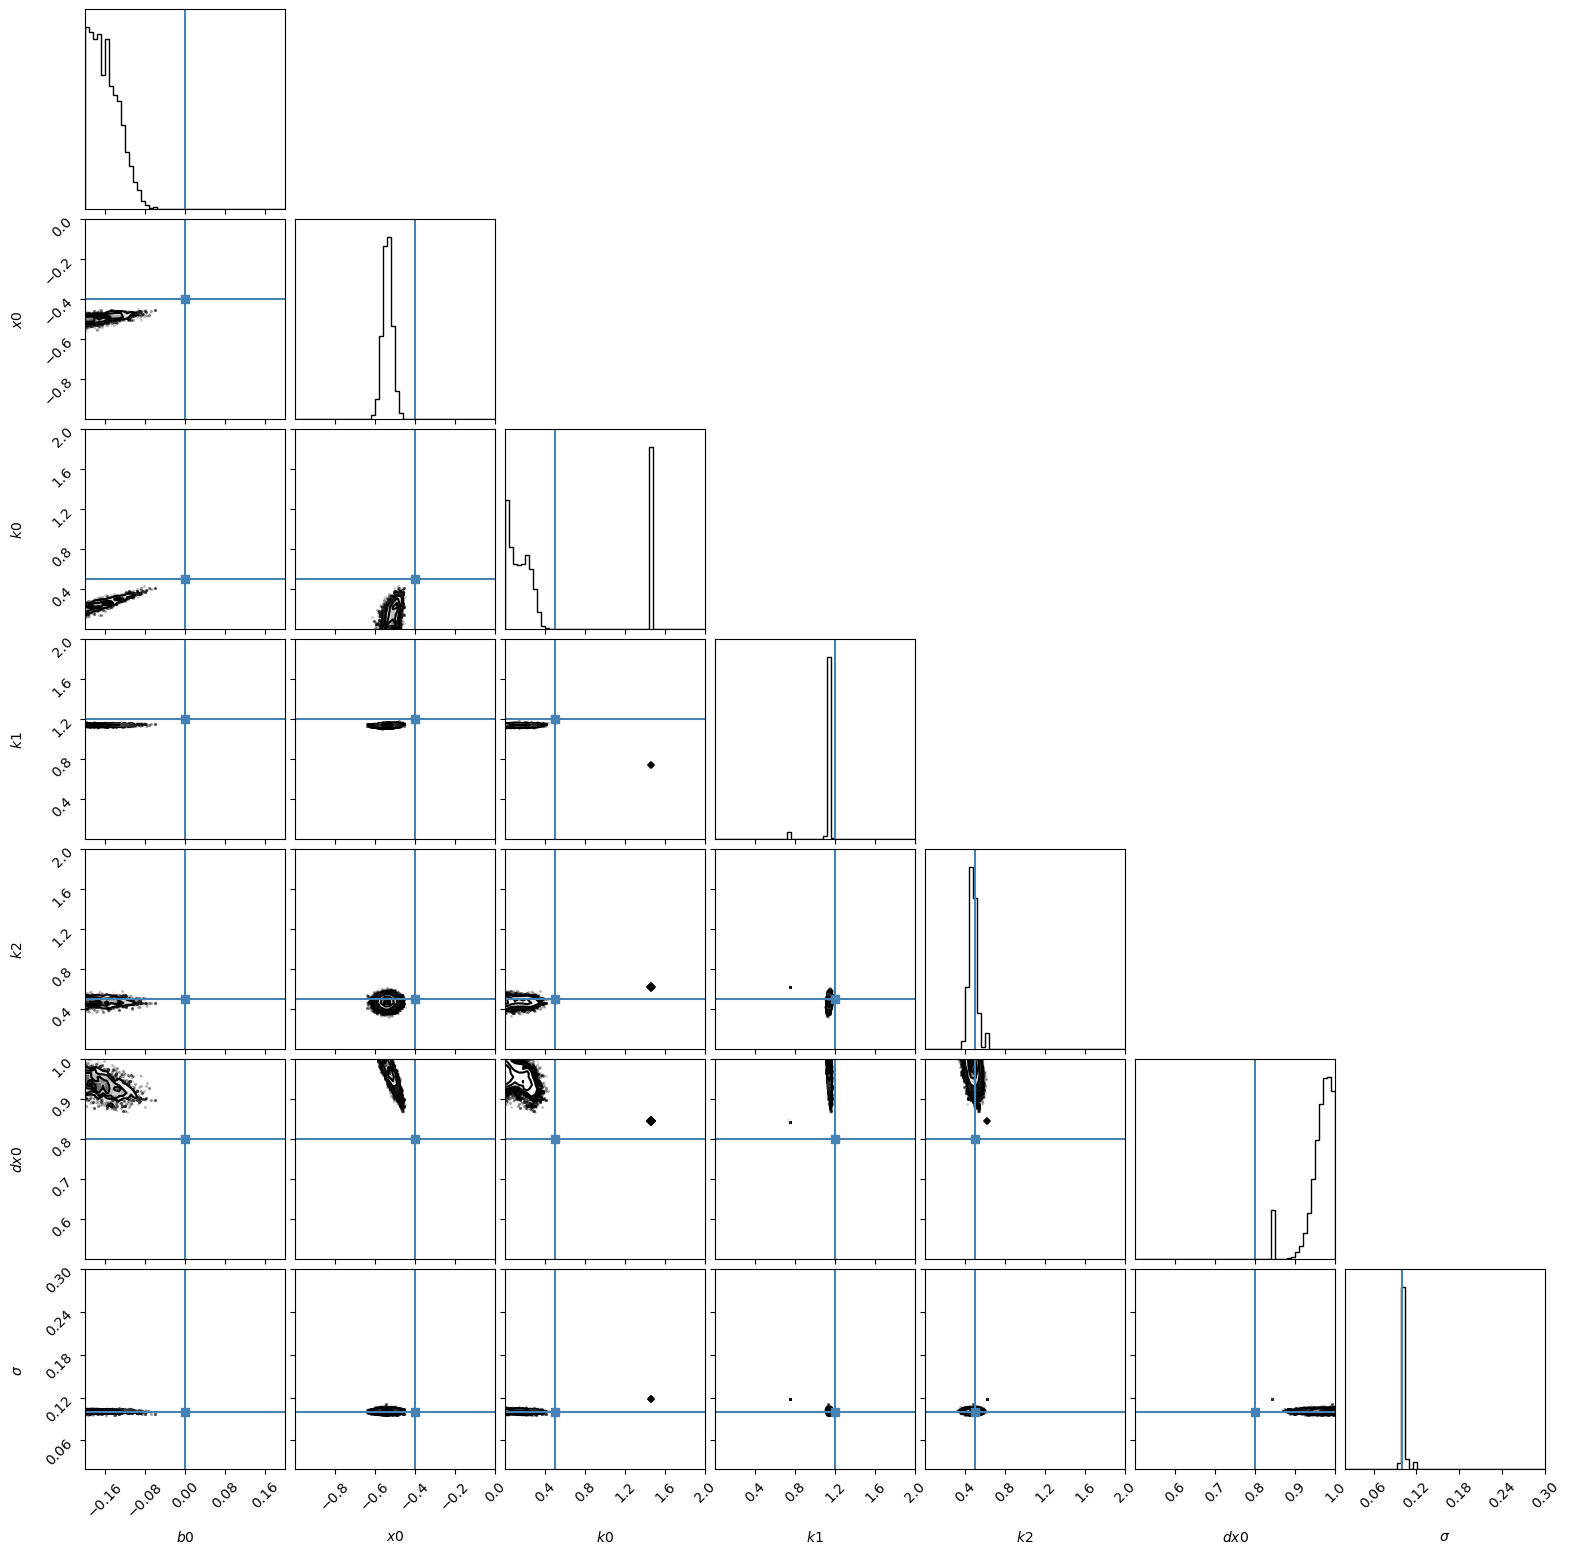

In [ ]:
fig = corner(
    sampler.get_chain(flat=True, discard=20000),
    truths=[0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1],
    # truths=params_ml_piecewise,
    labels=["$b0$", "$x0$", "$k0$", "$k1$", "$k2$", "$dx0$", "$\sigma$"],
    range=[(-0.2, 0.2), (-1, 0), (0, 2), (0, 2), (0, 2), (0.5, 1), (0.02, 0.3)],
    bins=50,
    # plot_datapoints=False,
    plot_density=True,
)

## Compare

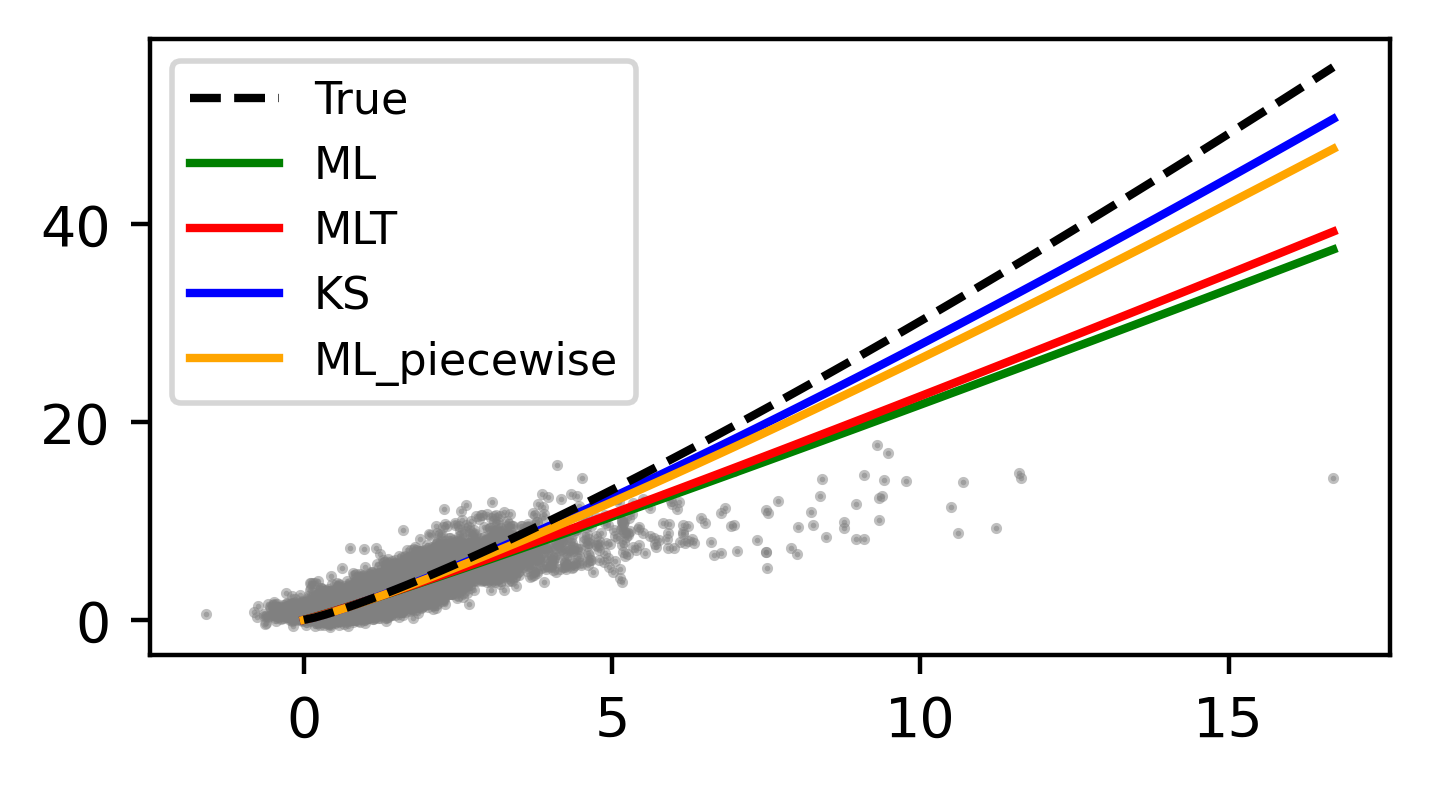

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k_main * np.log10(xx) + b_main)
yy_ML = 10**(params_ml[0] * np.log10(xx) + params_ml[1])
yy_MLT = 10**(params_ml_t[0] * np.log10(xx) + params_ml_t[1])
yy_KS = 10**(params_mean[0] * np.log10(xx) + params_mean[1])
# yy_ML_saturated = 10**saturated_linear_smooth(np.log10(xx),
#                                               *params_ml_saturated_c[:-1])
yy_ML_saturated = 10**(params_ml_piecewise[3] * np.log10(xx) +
                       params_ml_piecewise[0] +
                       params_ml_piecewise[2] * params_ml_piecewise[1] -
                       params_ml_piecewise[3] * params_ml_piecewise[1])

plt.plot(xx, yy, color='black', label='True', zorder=10, linestyle='--')
plt.plot(xx, yy_ML, color='green', label='ML')
plt.plot(xx, yy_MLT, color='red', label='MLT')
plt.plot(xx, yy_KS, color='blue', label='KS')
plt.plot(xx, yy_ML_saturated, color='orange', label='ML_piecewise')

plt.legend(fontsize=8)